100%|██████████| 9.91M/9.91M [00:00<00:00, 58.4MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.63MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.3MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.80MB/s]


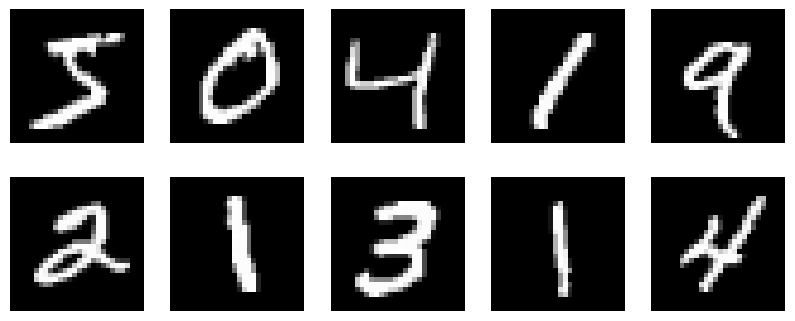

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.autograd import Variable
import numpy as np
import math
import matplotlib.pyplot as plt
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

def log_normal_diag(x, mean, log_var, dim=None):
    log_normal = -0.5 * (log_var + torch.pow(x - mean, 2) / torch.exp(log_var))
    return torch.sum(log_normal, dim=dim) if dim else log_normal

def log_bernoulli(x, mean, dim=None):
    probs = torch.clamp(mean, min=1e-5, max=1 - 1e-5)
    log_bern = x * torch.log(probs) + (1 - x) * torch.log(1 - probs)
    return torch.sum(log_bern, dim=dim) if dim else log_bern

# کلاس پایه برای لایه‌ها
class GatedDense(nn.Module):
    def __init__(self, input_size, output_size):
        super().__init__()
        self.fc = nn.Linear(input_size, output_size)
        self.gate = nn.Linear(input_size, output_size)
    def forward(self, x):
        return self.fc(x) * torch.sigmoid(self.gate(x))

class VAE(nn.Module):
    def __init__(self, input_size=784, hidden_size=300, latent_size=40, prior='standard', num_components=500):
        super().__init__()
        self.input_size = input_size
        self.latent_size = latent_size
        self.prior = prior
        self.num_components = num_components

        # Encoder
        self.encoder = nn.Sequential(
            GatedDense(input_size, hidden_size),
            GatedDense(hidden_size, hidden_size)
        )
        self.z_mean = nn.Linear(hidden_size, latent_size)
        self.z_logvar = nn.Linear(hidden_size, latent_size)
        nn.init.xavier_uniform_(self.z_mean.weight)
        nn.init.xavier_uniform_(self.z_logvar.weight)

        # Decoder
        self.decoder = nn.Sequential(
            GatedDense(latent_size, hidden_size),
            GatedDense(hidden_size, hidden_size)
        )
        self.x_mean = nn.Linear(hidden_size, input_size)

        if prior == 'vampprior':
            self.pseudo_inputs = nn.Parameter(torch.randn(num_components, input_size) * 0.01 - 0.05)

    def reparameterize(self, mean, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mean + eps * std

    def encode(self, x):
        h = self.encoder(x)
        return self.z_mean(h), self.z_logvar(h)

    def decode(self, z):
        h = self.decoder(z)
        return torch.sigmoid(self.x_mean(h))

    def forward(self, x):
        z_mean, z_logvar = self.encode(x.view(-1, self.input_size))
        z = self.reparameterize(z_mean, z_logvar)
        return self.decode(z), z, z_mean, z_logvar

    def log_p_z(self, z):
        if self.prior == 'standard':
            return -0.5 * torch.sum(z**2, dim=1)
        elif self.prior == 'vampprior':
            pseudo = self.pseudo_inputs
            means, logvars = self.encode(pseudo)
            z_expand = z.unsqueeze(1)
            means = means.unsqueeze(0)
            logvars = logvars.unsqueeze(0)
            a = log_normal_diag(z_expand, means, logvars, dim=2) - math.log(self.num_components)
            a_max, _ = torch.max(a, 1)
            return a_max + torch.log(torch.sum(torch.exp(a - a_max.unsqueeze(1)), 1))

    def loss(self, x, recon_x, z, z_mean, z_logvar, beta=1.0):
        RE = -log_bernoulli(x.view(-1, self.input_size), recon_x, dim=1)
        log_p = self.log_p_z(z)
        log_q = log_normal_diag(z, z_mean, z_logvar, dim=1)
        KL = -(log_p - log_q)
        return torch.mean(RE + beta * KL), torch.mean(RE), torch.mean(KL)

# بارگذاری Dynamic MNIST
transform = transforms.Compose([transforms.ToTensor()])
train_dataset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
test_dataset = datasets.MNIST(root='./data', train=False, download=True, transform=transform)

def dynamic_binarize(data):
    return torch.bernoulli(data)

# نمایش نمونه‌ها
fig, axs = plt.subplots(2, 5, figsize=(10, 4))
for i in range(10):
    img = train_dataset[i][0].squeeze()
    axs[i//5, i%5].imshow(img, cmap='gray')
    axs[i//5, i%5].axis('off')
plt.show()

Epoch 1: Loss 181.77, RE 181.34, KL 42.72
Epoch 2: Loss 156.38, RE 155.76, KL 30.97
Epoch 3: Loss 150.69, RE 149.95, KL 24.72
Epoch 4: Loss 147.36, RE 146.47, KL 22.21
Epoch 5: Loss 145.06, RE 144.07, KL 19.71
Epoch 6: Loss 143.15, RE 142.09, KL 17.70
Epoch 7: Loss 141.51, RE 140.37, KL 16.28
Epoch 8: Loss 140.23, RE 139.01, KL 15.15
Epoch 9: Loss 139.26, RE 137.99, KL 14.20
Epoch 10: Loss 138.34, RE 137.00, KL 13.42
Epoch 11: Loss 137.61, RE 136.21, KL 12.78
Epoch 12: Loss 136.93, RE 135.46, KL 12.26
Epoch 13: Loss 136.45, RE 134.91, KL 11.84
Epoch 14: Loss 135.99, RE 134.39, KL 11.41
Epoch 15: Loss 135.52, RE 133.84, KL 11.17
Epoch 16: Loss 135.32, RE 133.57, KL 10.93
Epoch 17: Loss 134.99, RE 133.18, KL 10.64
Epoch 18: Loss 134.52, RE 132.65, KL 10.43
Epoch 19: Loss 134.31, RE 132.36, KL 10.27
Epoch 20: Loss 133.95, RE 131.94, KL 10.06
Epoch 21: Loss 133.82, RE 131.73, KL 9.94
Epoch 22: Loss 133.39, RE 131.24, KL 9.80
Epoch 23: Loss 133.25, RE 131.02, KL 9.69
Epoch 24: Loss 133.13, 

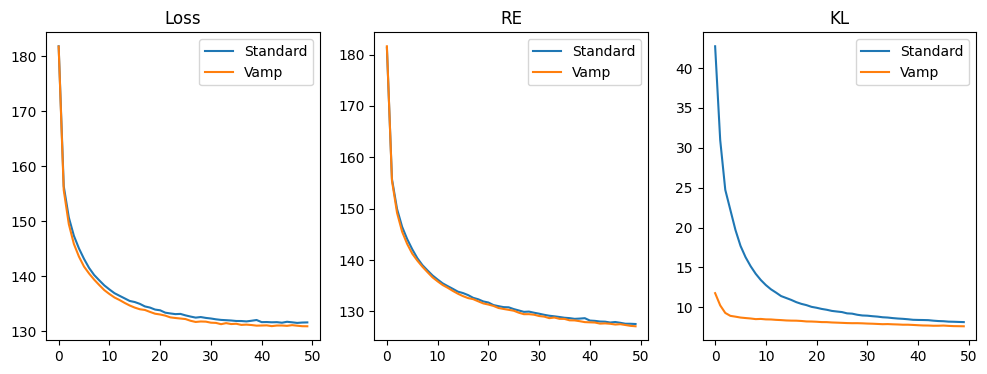

In [ ]:
# تابع آموزش
def train_model(model, train_loader, epochs=50, warmup=100, lr=5e-4):
    optimizer = optim.Adam(model.parameters(), lr=lr)
    losses, res, kls = [], [], []
    for epoch in range(1, epochs + 1):
        model.train()
        beta = min(1, epoch / warmup)
        total_loss, total_re, total_kl = 0, 0, 0
        for data, _ in train_loader:
            data = data.to(device)
            x = dynamic_binarize(data)
            optimizer.zero_grad()
            recon, z, mean, logvar = model(x)
            loss, re, kl = model.loss(x, recon, z, mean, logvar, beta)
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
            total_re += re.item()
            total_kl += kl.item()
        losses.append(total_loss / len(train_loader))
        res.append(total_re / len(train_loader))
        kls.append(total_kl / len(train_loader))
        print(f'Epoch {epoch}: Loss {losses[-1]:.2f}, RE {res[-1]:.2f}, KL {kls[-1]:.2f}')
    return losses, res, kls

train_loader = DataLoader(train_dataset, batch_size=100, shuffle=True)
vae_standard_low = VAE(latent_size=2, prior='standard').to(device)
losses_std_low, re_std_low, kl_std_low = train_model(vae_standard_low, train_loader)

vae_vamp_low = VAE(latent_size=2, prior='vampprior').to(device)
losses_vamp_low, re_vamp_low, kl_vamp_low = train_model(vae_vamp_low, train_loader)

plt.figure(figsize=(12,4))
plt.subplot(131); plt.plot(losses_std_low, label='Standard'); plt.plot(losses_vamp_low, label='Vamp'); plt.legend(); plt.title('Loss')
plt.subplot(132); plt.plot(re_std_low, label='Standard'); plt.plot(re_vamp_low, label='Vamp'); plt.legend(); plt.title('RE')
plt.subplot(133); plt.plot(kl_std_low, label='Standard'); plt.plot(kl_vamp_low, label='Vamp'); plt.legend(); plt.title('KL')
plt.show()

In [4]:
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

transform = transforms.Compose([transforms.ToTensor()])

test_dataset = datasets.MNIST(
    root='./data', 
    train=False, 
    download=True,         
    transform=transform
)

test_loader = DataLoader(
    test_dataset, 
    batch_size=100,        
    shuffle=False          
)

print(f"Len Test loader : {len(test_loader)}")

Test loader آماده است — تعداد بچ‌ها: 100


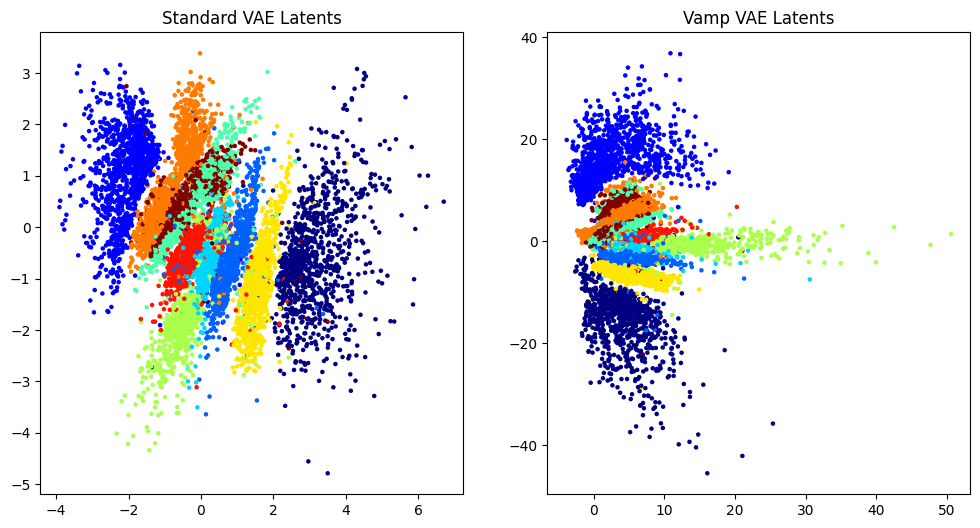

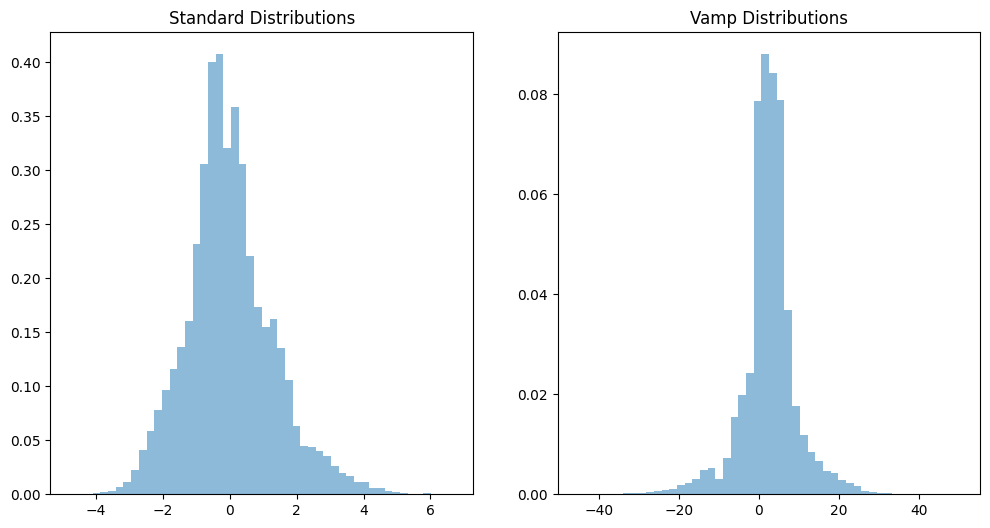

In [ ]:

def get_latents(model, loader):
    latents, labels = [], []
    model.eval()
    for data, label in loader:
        data = data.to(device)
        _, z, _, _ = model(data)
        latents.append(z.detach().cpu().numpy())
        labels.append(label.numpy())
    return np.concatenate(latents), np.concatenate(labels)

z_std, y_std = get_latents(vae_standard_low, test_loader)
z_vamp, y_vamp = get_latents(vae_vamp_low, test_loader)

plt.figure(figsize=(12,6))
plt.subplot(121); plt.scatter(z_std[:,0], z_std[:,1], c=y_std, cmap='jet', s=5); plt.title('Standard VAE Latents')
plt.subplot(122); plt.scatter(z_vamp[:,0], z_vamp[:,1], c=y_vamp, cmap='jet', s=5); plt.title('Vamp VAE Latents')
plt.show()

plt.figure(figsize=(12,6))
plt.subplot(121); plt.hist(z_std.flatten(), bins=50, density=True, alpha=0.5, label='Posterior'); plt.title('Standard Distributions')
plt.subplot(122); plt.hist(z_vamp.flatten(), bins=50, density=True, alpha=0.5, label='Posterior'); plt.title('Vamp Distributions')
plt.show()

Epoch 1: Loss 160.50, RE 158.71, KL 178.60
Epoch 2: Loss 92.55, RE 89.52, KL 151.59
Epoch 3: Loss 76.09, RE 72.22, KL 129.09
Epoch 4: Loss 69.72, RE 65.13, KL 114.91
Epoch 5: Loss 66.26, RE 60.94, KL 106.27
Epoch 6: Loss 64.15, RE 58.12, KL 100.61
Epoch 7: Loss 62.59, RE 55.82, KL 96.68
Epoch 8: Loss 61.62, RE 54.14, KL 93.45
Epoch 9: Loss 61.05, RE 52.88, KL 90.74
Epoch 10: Loss 60.63, RE 51.79, KL 88.41
Epoch 11: Loss 60.35, RE 50.84, KL 86.44
Epoch 12: Loss 60.24, RE 50.07, KL 84.70
Epoch 13: Loss 60.28, RE 49.49, KL 82.99
Epoch 14: Loss 60.39, RE 48.98, KL 81.46
Epoch 15: Loss 60.66, RE 48.67, KL 79.95
Epoch 16: Loss 60.89, RE 48.31, KL 78.63
Epoch 17: Loss 61.16, RE 48.02, KL 77.31
Epoch 18: Loss 61.52, RE 47.84, KL 76.00
Epoch 19: Loss 61.90, RE 47.69, KL 74.81
Epoch 20: Loss 62.28, RE 47.55, KL 73.66
Epoch 21: Loss 62.72, RE 47.52, KL 72.40
Epoch 22: Loss 63.11, RE 47.42, KL 71.31
Epoch 23: Loss 63.65, RE 47.49, KL 70.24
Epoch 24: Loss 64.12, RE 47.51, KL 69.20
Epoch 25: Loss 64

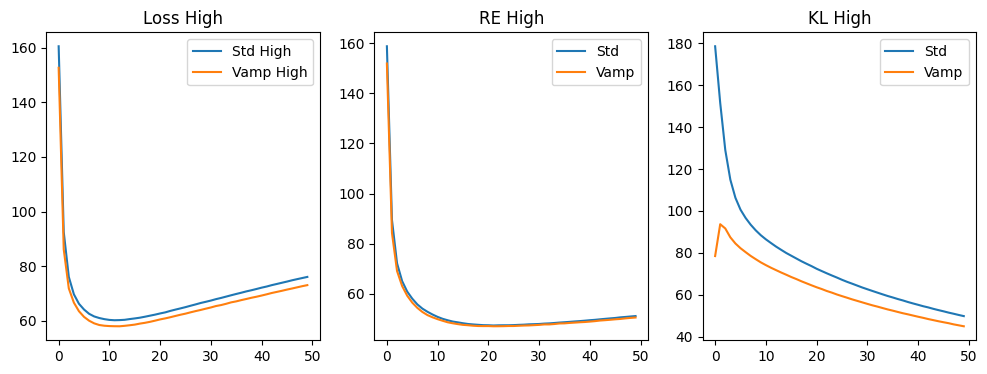

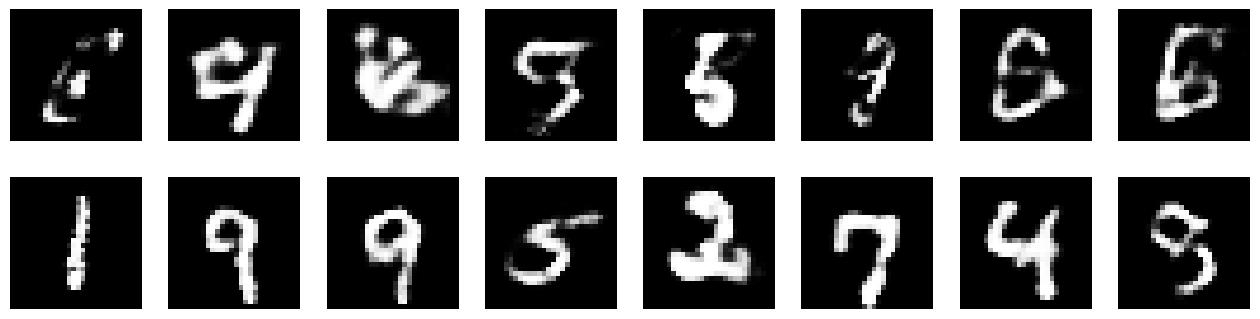

In [ ]:
vae_standard_high = VAE(latent_size=40, prior='standard').to(device)
losses_std_high, re_std_high, kl_std_high = train_model(vae_standard_high, train_loader)

vae_vamp_high = VAE(latent_size=40, prior='vampprior').to(device)
losses_vamp_high, re_vamp_high, kl_vamp_high = train_model(vae_vamp_high, train_loader)

plt.figure(figsize=(12,4))
plt.subplot(131); plt.plot(losses_std_high, label='Std High'); plt.plot(losses_vamp_high, label='Vamp High'); plt.legend(); plt.title('Loss High')
plt.subplot(132); plt.plot(re_std_high, label='Std'); plt.plot(re_vamp_high, label='Vamp'); plt.legend(); plt.title('RE High')
plt.subplot(133); plt.plot(kl_std_high, label='Std'); plt.plot(kl_vamp_high, label='Vamp'); plt.legend(); plt.title('KL High')
plt.show()

def generate_samples(model, n=8):
    model.eval()
    with torch.no_grad():
        if model.prior == 'standard':
            z = torch.randn(n, model.latent_size).to(device)
        else:
            idx = torch.randint(0, model.num_components, (n,))
            pseudo = model.pseudo_inputs[idx]
            mean, logvar = model.encode(pseudo)
            z = model.reparameterize(mean, logvar)
        samples = model.decode(z).cpu().numpy().reshape(-1, 28, 28)
    return samples

samples_std = generate_samples(vae_standard_high)
samples_vamp = generate_samples(vae_vamp_high)

fig, axs = plt.subplots(2, 8, figsize=(16,4))
for i in range(8):
    axs[0,i].imshow(samples_std[i], cmap='gray'); axs[0,i].axis('off')
    axs[1,i].imshow(samples_vamp[i], cmap='gray'); axs[1,i].axis('off')
plt.show()

In [ ]:

def check_active_units(model, loader):
    model.eval()
    kl_dims = np.zeros(model.latent_size)
    count = 0
    for data, _ in loader:
        data = data.to(device)
        _, z, mean, logvar = model(data)
        kl = 0.5 * (torch.exp(logvar) + mean**2 - 1 - logvar)
        kl_dims += kl.mean(0).detach().cpu().numpy()
        count += 1
    return kl_dims / count > 0.01

active_std = check_active_units(vae_standard_high, test_loader)
active_vamp = check_active_units(vae_vamp_high, test_loader)
print(f'Standard Active Units: {active_std.sum()}')
print(f'Vamp Active Units: {active_vamp.sum()}')

Standard Active Units: 40
Vamp Active Units: 40


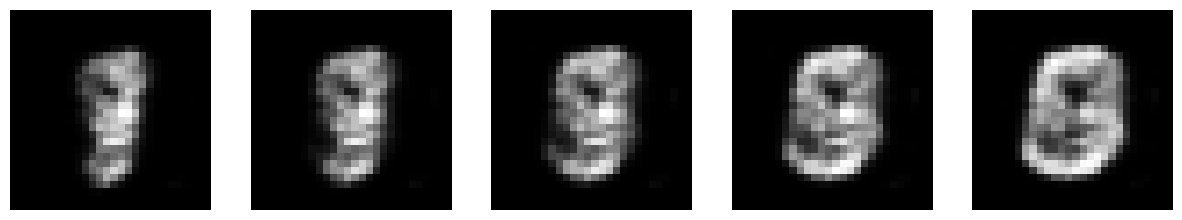

In [ ]:
z_test, _ = get_latents(vae_vamp_high, test_loader)  # مثلاً برای Vamp
pca = PCA(n_components=2)
pca.fit(z_test)
mean_z = z_test.mean(0)
directions = pca.components_

fig, axs = plt.subplots(1, 5, figsize=(15,3))
for i, alpha in enumerate(np.linspace(-3, 3, 5)):
    z_trav = torch.from_numpy(mean_z + alpha * directions[0]).float().to(device).unsqueeze(0)
    img = vae_vamp_high.decode(z_trav).cpu().detach().numpy().reshape(28,28)
    axs[i].imshow(img, cmap='gray'); axs[i].axis('off')
plt.show()

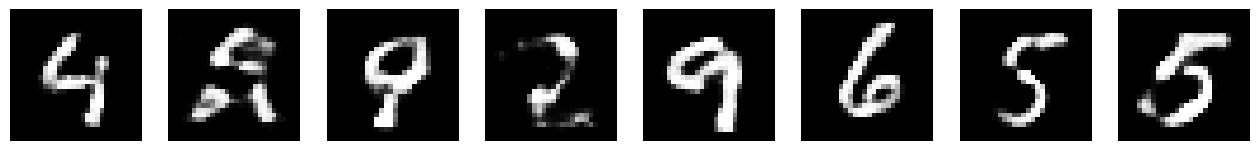

In [ ]:
if vae_vamp_high.prior == 'vampprior':
    pseudo = vae_vamp_high.pseudo_inputs[:8]
    mean, logvar = vae_vamp_high.encode(pseudo)
    z = vae_vamp_high.reparameterize(mean, logvar)
    imgs = vae_vamp_high.decode(z).detach().cpu().numpy().reshape(-1,28,28)
    fig, axs = plt.subplots(1,8,figsize=(16,2))
    for i in range(8):
        axs[i].imshow(imgs[i], cmap='gray'); axs[i].axis('off')
    plt.show()

In [16]:
def iwae_log_likelihood(model, loader, L=100):
    model.eval()
    ll = 0.0
    N = 0
    with torch.no_grad():
        for data, _ in loader:
            data = data.to(device)
            x = data.view(-1, model.input_size)
            log_w = []
            for _ in range(L):
                z_mean, z_logvar = model.encode(x)
                z = model.reparameterize(z_mean, z_logvar)
                recon = model.decode(z)
                log_pxz = log_bernoulli(x, recon, dim=1)
                log_pz  = model.log_p_z(z)
                log_qz  = log_normal_diag(z, z_mean, z_logvar, dim=1)
                log_w.append(log_pxz + log_pz - log_qz)
            log_w = torch.logsumexp(torch.stack(log_w), dim=0) - math.log(L)
            ll += log_w.sum().item()
            N += log_w.size(0)
    return ll / N

# استفاده
small_test_loader = DataLoader(test_dataset, batch_size=50, shuffle=False)

ll_std  = iwae_log_likelihood(vae_standard_high, small_test_loader, L=100)
ll_vamp = iwae_log_likelihood(vae_vamp_high,   small_test_loader, L=100)

print(f"Standard VAE  IWAE-100 LL: {ll_std:.2f}")
print(f"VampPrior VAE IWAE-100 LL: {ll_vamp:.2f}")

Standard VAE  IWAE-100 LL: -106.22
VampPrior VAE IWAE-100 LL: -101.43


In [ ]:
print("Hello")